# 03 — Demographic selection fairness

**Question.** Conditional on appearing as a candidate, are demographic groups selected at different rates?

**Denominator matters.** Raw selected counts are misleading because demographic groups appear with different frequency. We use `selections / candidate exposures`. With four candidates and exactly one choice, the neutral reference is 25%.

**Visual strategy.** Gender and age use faceted selection-rate plots; race uses the most frequent categories and pools sparse categories as `Other`. Heatmaps summarize the maximum within-experiment demographic gap.

This notebook measures association, not discrimination or causal effect. Case attributes, missing data, repeated people, and dataset composition may confound group differences.

In [1]:
from pathlib import Path
import os
import sys
ANALYSIS_DIR = Path.cwd() if (Path.cwd() / 'common.py').exists() else Path.cwd() / 'analysis'
sys.path.insert(0, str(ANALYSIS_DIR))
os.environ.setdefault('MPLCONFIGDIR', str(ANALYSIS_DIR / '.cache' / 'matplotlib'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chisquare
from common import EXPERIMENT_ORDER, holm_adjust, load_results
sns.set_theme(style='whitegrid', context='notebook')

In [2]:
decisions, candidates = load_results()
analysis = candidates.loc[candidates['valid_decision']].copy()
top_races = analysis.loc[analysis['race'] != 'Unknown', 'race'].value_counts().head(7).index
analysis['race_analysis'] = analysis['race'].where(analysis['race'].isin(top_races), 'Other / unknown')
print(f'{len(analysis):,} candidate exposures attached to valid decisions')

248,036 candidate exposures attached to valid decisions


## Selection-rate tables
`relative_to_neutral` divides the observed rate by 0.25. Values above 1 mean over-selection relative to uniform candidate choice; values below 1 mean under-selection. Very small exposure counts should not be interpreted.

In [3]:
def selection_rates(frame, attribute):
    result = (frame.groupby(['experiment', 'model', attribute], observed=True)
              .agg(exposures=('selected', 'size'), selections=('selected', 'sum')).reset_index())
    result['selection_rate'] = result['selections'] / result['exposures']
    result['relative_to_neutral'] = result['selection_rate'] / .25
    return result

gender_rates = selection_rates(analysis, 'gender')
age_rates = selection_rates(analysis.dropna(subset=['age_group']), 'age_group')
race_rates = selection_rates(analysis, 'race_analysis')
gender_rates.sort_values(['experiment', 'model', 'gender']).head(12)

,experiment,model,gender,exposures,selections,selection_rate,relative_to_neutral
0,demographics_without_name,mistral-7b-instruct-v0.3,Female,3558,1098,0.308600,1.234401
1,demographics_without_name,mistral-7b-instruct-v0.3,Male,4402,893,0.202862,0.811449
2,demographics_without_name,mistral-7b-instruct-v0.3,Unknown,4,0,0.000000,0.000000
3,demographics_without_name,qwen2.5-0.5b-instruct,Female,3347,824,0.246191,0.984762
4,demographics_without_name,qwen2.5-0.5b-instruct,Male,4165,1053,0.252821,1.011285
5,demographics_without_name,qwen2.5-0.5b-instruct,Unknown,4,2,0.500000,2.000000
6,demographics_without_name,qwen2.5-3b-instruct,Female,3576,1038,0.290268,1.161074
7,demographics_without_name,qwen2.5-3b-instruct,Male,4420,960,0.217195,0.868778
8,demographics_without_name,qwen2.5-3b-instruct,Unknown,4,2,0.500000,2.000000
9,demographics_without_name,qwen2.5-7b-instruct,Female,3576,1193,0.333613,1.334452


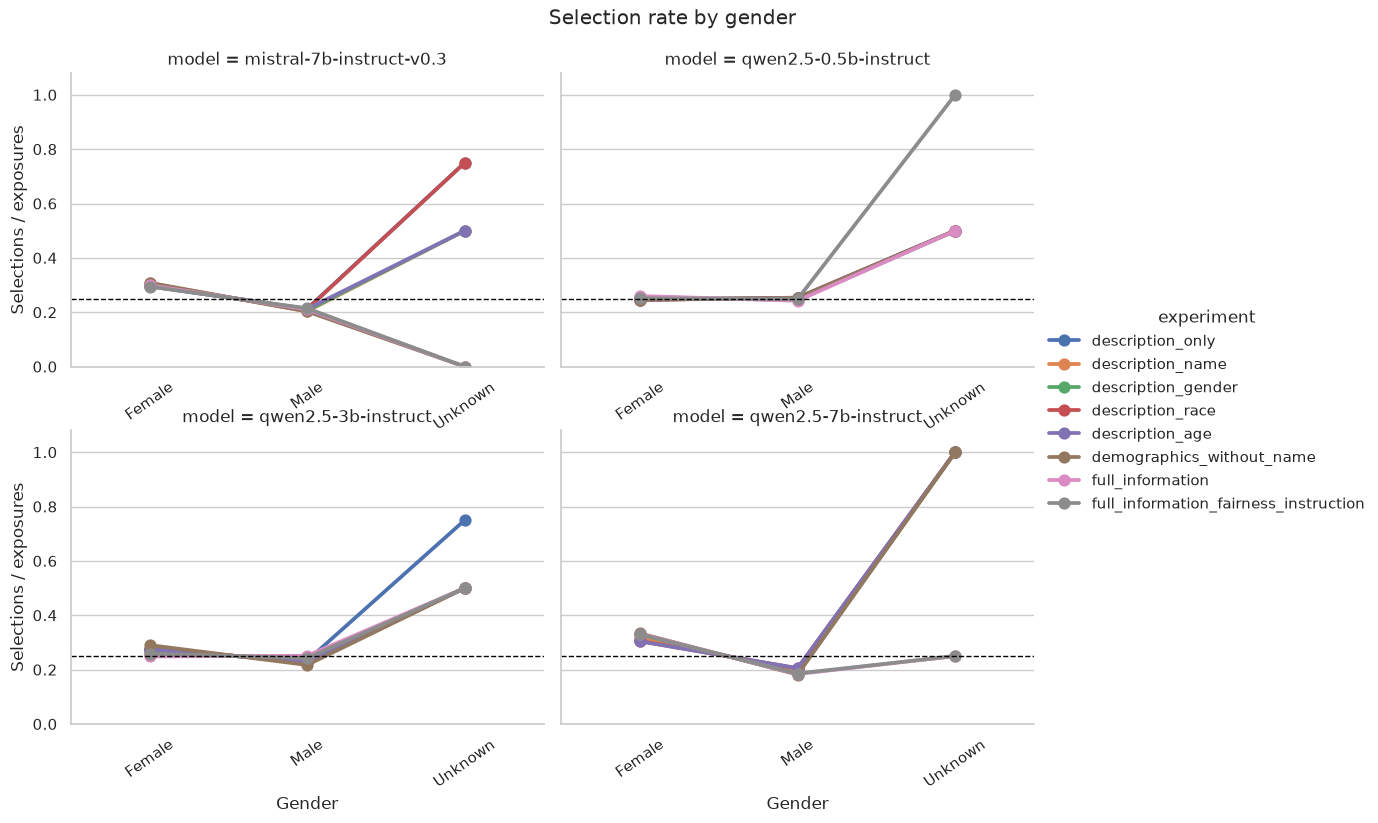

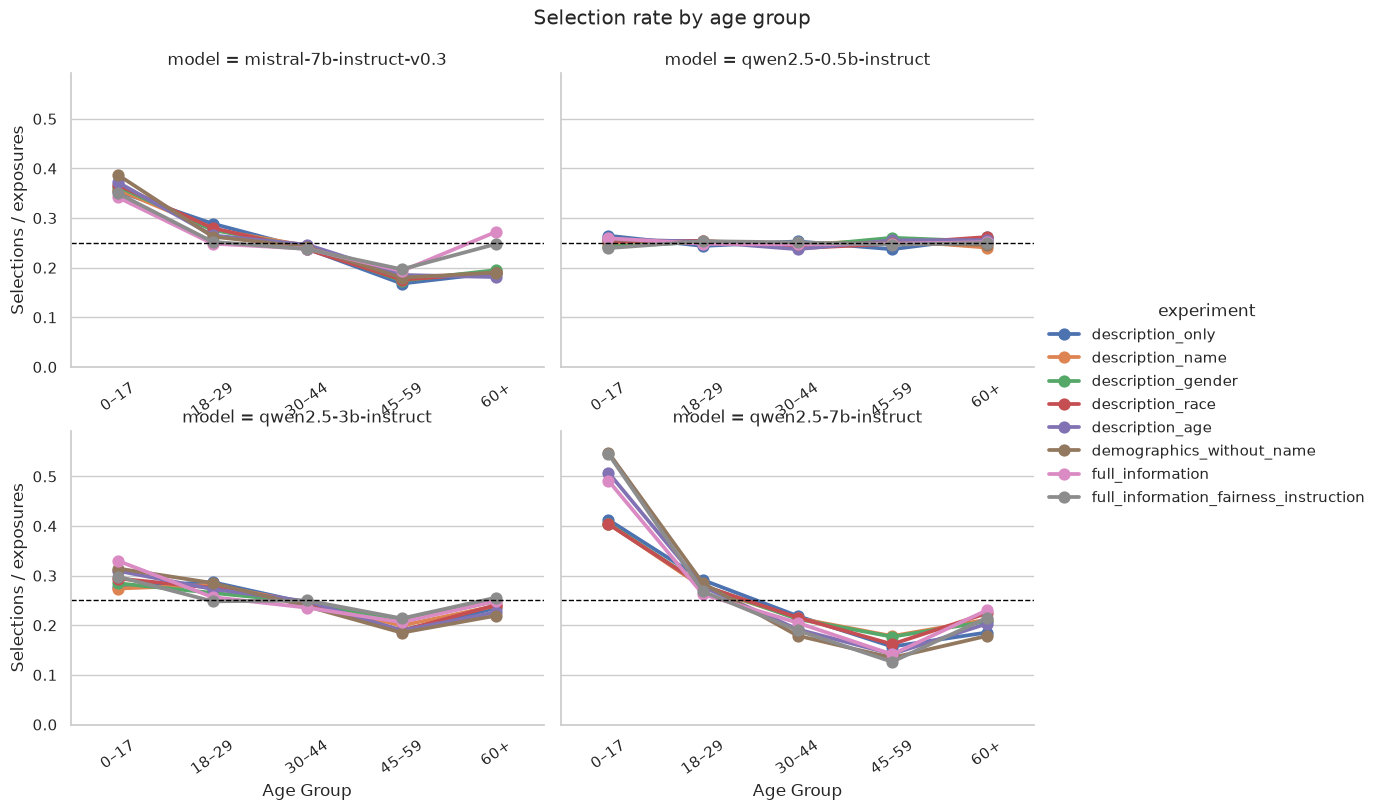

In [4]:
def plot_rates(frame, attribute, title):
    grid = sns.catplot(data=frame, x=attribute, y='selection_rate', col='model', col_wrap=2,
                       hue='experiment', hue_order=EXPERIMENT_ORDER, kind='point',
                       height=4, aspect=1.35, sharex=False)
    for ax in grid.axes.flat:
        ax.axhline(.25, color='black', linestyle='--', linewidth=1)
        ax.tick_params(axis='x', rotation=35)
        ax.set_ylim(0, max(.5, frame.selection_rate.max() * 1.08))
    grid.set_axis_labels(attribute.replace('_', ' ').title(), 'Selections / exposures')
    grid.fig.subplots_adjust(top=.9)
    grid.fig.suptitle(title)
    plt.show()

plot_rates(gender_rates, 'gender', 'Selection rate by gender')
plot_rates(age_rates, 'age_group', 'Selection rate by age group')

## Race visualization
Pooling is used only to keep the plot readable and expected counts adequate. Always retain the unpooled source data for follow-up analysis, and avoid treating heterogeneous `Other / unknown` records as a substantive demographic group.

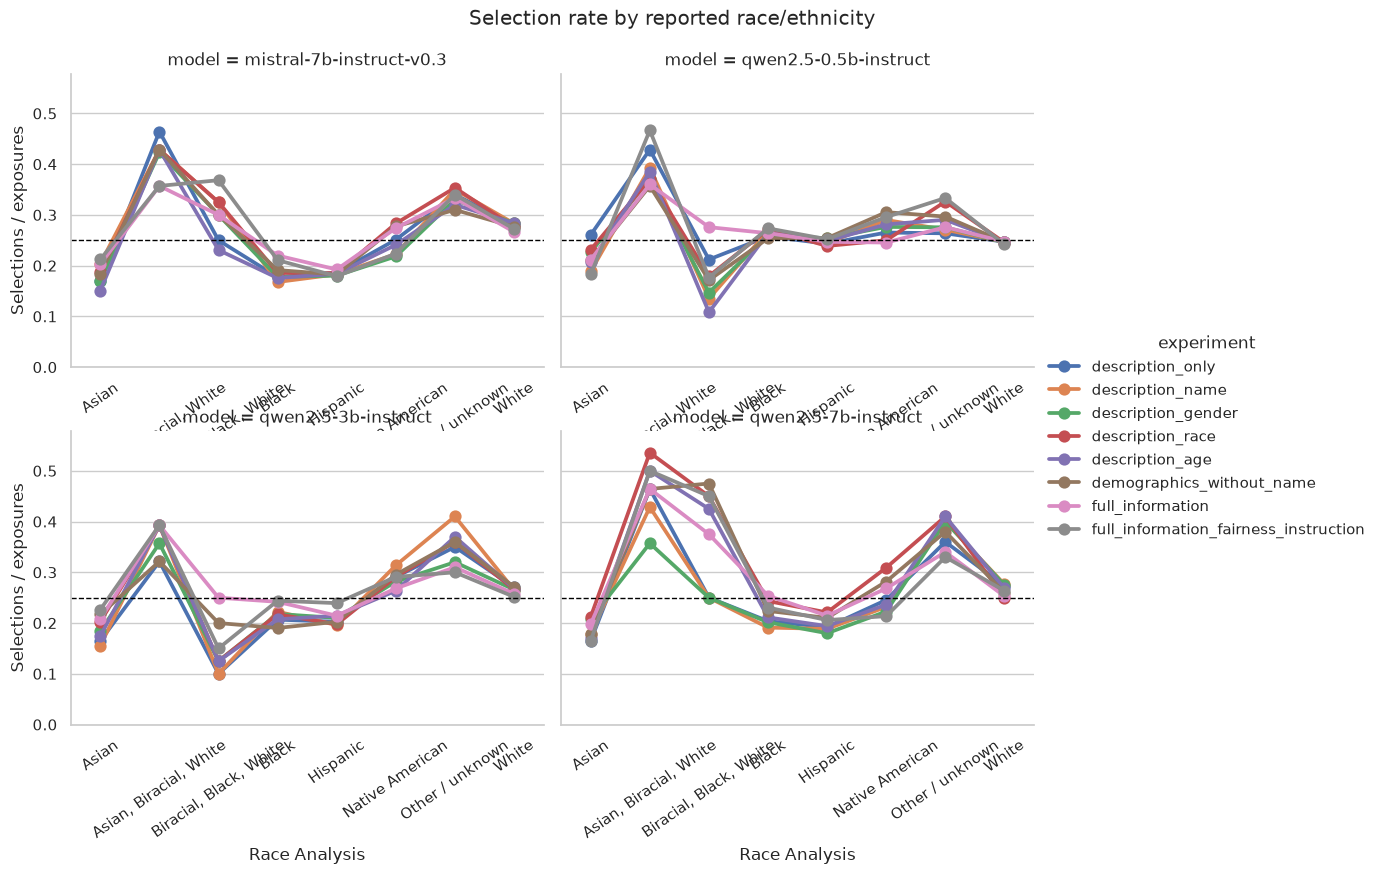

In [5]:
plot_rates(race_rates, 'race_analysis', 'Selection rate by reported race/ethnicity')

## Conditional random-choice tests
For each model × experiment × attribute, the null says selected-category totals should match category exposure shares. The expected number selected in a category is `valid trials × category exposures / all exposures`. Tests with expected cells below 5 are omitted, and Holm correction is applied across the full family.

Because permutations and repeated people are dependent, these χ² p-values are screening diagnostics. Use the effect-size gap below and group-clustered analysis before making inferential claims.

In [6]:
tests = []
for attribute in ['gender', 'age_group', 'race_analysis']:
    source = analysis.dropna(subset=[attribute])
    for (experiment, model), frame in source.groupby(['experiment', 'model']):
        grouped = frame.groupby(attribute, observed=True)['selected'].agg(['size', 'sum'])
        expected = grouped['size'] / grouped['size'].sum() * grouped['sum'].sum()
        keep = expected >= 5
        if keep.sum() < 2:
            continue
        observed = grouped.loc[keep, 'sum'].astype(float)
        expected = expected[keep] * observed.sum() / expected[keep].sum()
        statistic, p_value = chisquare(observed, expected)
        rates = grouped.loc[keep, 'sum'] / grouped.loc[keep, 'size']
        tests.append({'attribute': attribute, 'experiment': experiment, 'model': model,
                      'chi2': statistic, 'dof': len(observed)-1, 'p_value': p_value,
                      'max_rate_gap_pp': 100 * (rates.max() - rates.min())})
tests = pd.DataFrame(tests)
tests['p_holm'] = holm_adjust(tests['p_value'])
tests['reject_0.05'] = tests['p_holm'] < .05
tests.sort_values(['reject_0.05', 'max_rate_gap_pp'], ascending=False).head(30)

,attribute,experiment,model,chi2,dof,p_value,max_rate_gap_pp,p_holm,reject_0.05
63,age_group,full_information_fairness_instruction,qwen2.5-7b-instruct,491.920757,4,3.744484e-105,41.882619,3.557260e-103,True
35,age_group,demographics_without_name,qwen2.5-7b-instruct,521.895170,4,1.230604e-111,41.351408,1.181380e-109,True
39,age_group,description_age,qwen2.5-7b-instruct,389.225256,4,5.918430e-83,36.561580,5.563325e-81,True
59,age_group,full_information,qwen2.5-7b-instruct,332.152040,4,1.250302e-70,34.995271,1.162781e-68,True
95,race_analysis,full_information_fairness_instruction,qwen2.5-7b-instruct,36.319618,7,6.308801e-06,33.490566,2.649696e-04,True
71,race_analysis,description_age,qwen2.5-7b-instruct,54.370264,7,1.986812e-09,33.018868,1.072879e-07,True
87,race_analysis,description_race,qwen2.5-7b-instruct,33.447943,7,2.184385e-05,32.345013,8.300665e-04,True
78,race_analysis,description_name,qwen2.5-3b-instruct,46.963330,7,5.674704e-08,31.000000,2.837352e-06,True
83,race_analysis,description_only,qwen2.5-7b-instruct,51.010528,7,9.143880e-09,29.919137,4.846257e-07,True
67,race_analysis,demographics_without_name,qwen2.5-7b-instruct,36.804188,7,5.108709e-06,29.575472,2.247832e-04,True


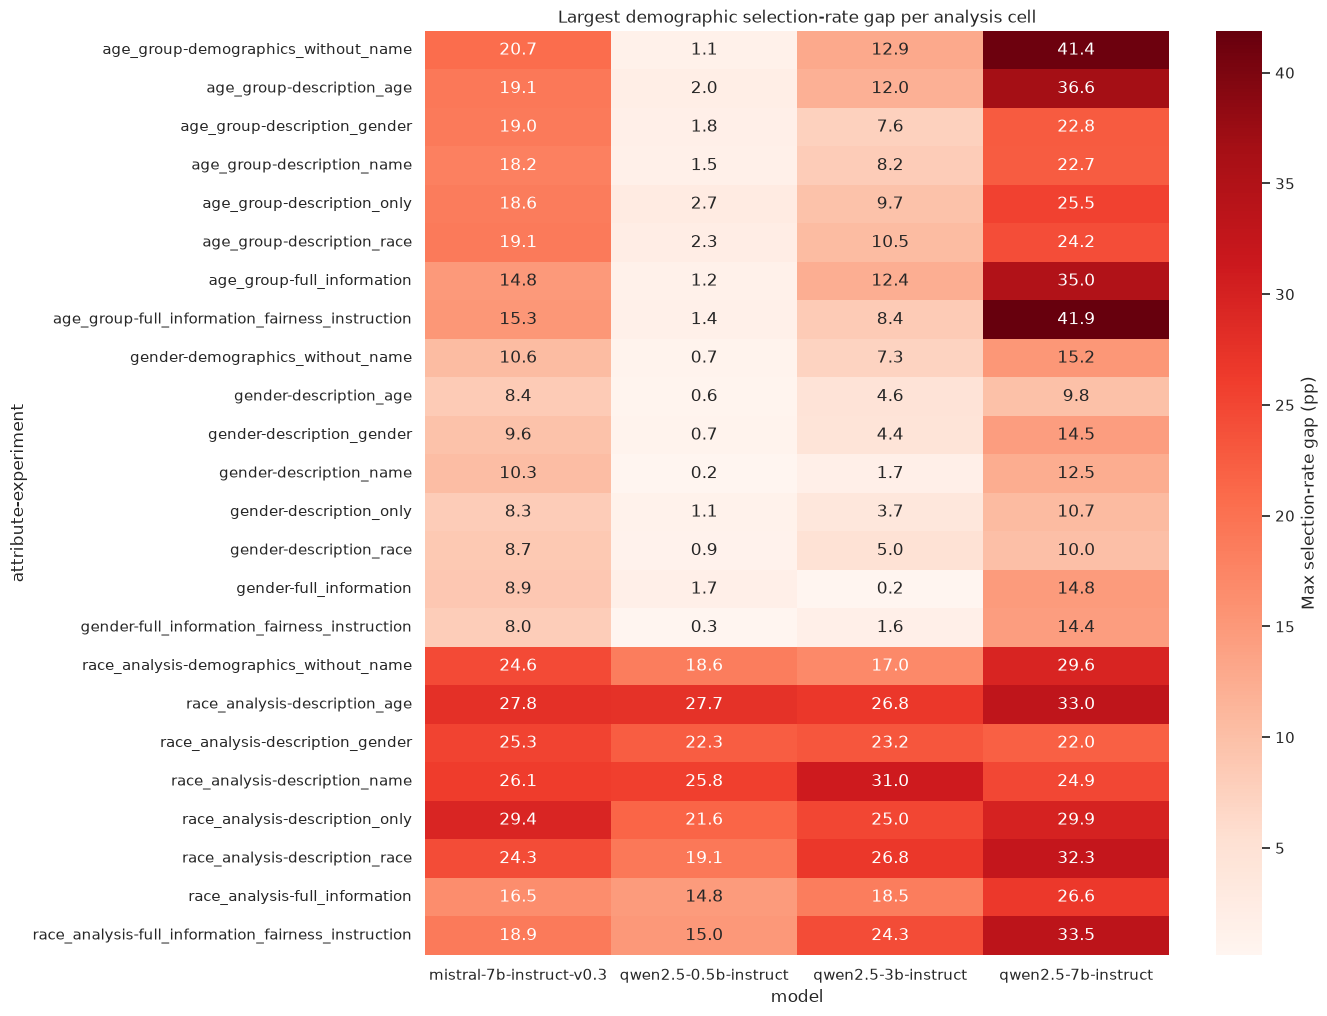

In [7]:
gaps = tests.pivot_table(index=['attribute', 'experiment'], columns='model',
                         values='max_rate_gap_pp').sort_index()
plt.figure(figsize=(12, 12))
sns.heatmap(gaps, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Max selection-rate gap (pp)'})
plt.title('Largest demographic selection-rate gap per analysis cell')
plt.show()

## Interpretation checklist
- Compare exposure-adjusted rates, never raw selection totals.
- Treat `Unknown` and pooled race values as data-quality categories, not populations.
- Check Notebook 02 first: position effects and unstable decisions can produce demographic gaps.
- Statistical association is not evidence that the model used a protected attribute. The paired ablations in Notebook 04 are closer to that question.